In [69]:
import pandas as pd 
#Imports
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import random
from datetime import datetime, timedelta
from matplotlib.ticker import FuncFormatter

In [70]:
import pandas as pd

df_vendas = pd.read_csv("vendas.csv", parse_dates=["Data_pedido"])

df_vendas.head()

,ID_pedido,Data_pedido,Nome_produto,Categoria,Preco_unitario,Quantidade,Id_cliente,Cidade,Estado
0,1001,2026-01-01 12:00:00,Webcam Full HD,Streaming,199.9,6,3752,Ceará,CE
1,1002,2026-01-01 12:00:00,Gabinete com iluminação RGB,Gabinetes,399.9,7,6897,Espírito Santo,ES
2,1003,2026-01-01 13:00:00,Controle sem fio,Periféricos,349.9,2,6475,Distrito Federal,DF
3,1004,2026-01-01 05:00:00,Headset gamer,Áudio,249.9,3,3626,Espírito Santo,ES
4,1005,2026-01-01 19:00:00,Placa de vídeo,Hardware,2499.9,3,6531,Alagoas,AL


In [71]:
df_vendas['Mes'] = df_vendas['Data_pedido'].dt.to_period('M')


In [72]:
df_vendas['Faturamento'] = df_vendas['Preco_unitario'] * df_vendas['Quantidade']

In [73]:
df_vendas.head()

,ID_pedido,Data_pedido,Nome_produto,Categoria,Preco_unitario,Quantidade,Id_cliente,Cidade,Estado,Mes,Faturamento
0,1001,2026-01-01 12:00:00,Webcam Full HD,Streaming,199.9,6,3752,Ceará,CE,2026-01,1199.4
1,1002,2026-01-01 12:00:00,Gabinete com iluminação RGB,Gabinetes,399.9,7,6897,Espírito Santo,ES,2026-01,2799.3
2,1003,2026-01-01 13:00:00,Controle sem fio,Periféricos,349.9,2,6475,Distrito Federal,DF,2026-01,699.8
3,1004,2026-01-01 05:00:00,Headset gamer,Áudio,249.9,3,3626,Espírito Santo,ES,2026-01,749.7
4,1005,2026-01-01 19:00:00,Placa de vídeo,Hardware,2499.9,3,6531,Alagoas,AL,2026-01,7499.7


In [74]:
faturamento_mensal = df_vendas.groupby('Mes')['Faturamento'].sum()

In [75]:
faturamento_mensal.index = faturamento_mensal.index.strftime('%Y-%m')

In [76]:
faturamento_mensal.map('R$ {:,.2f}'.format)

Mes
2026-01    R$ 341,825.36
2026-02    R$ 339,728.36
2026-03    R$ 331,730.14
2026-04    R$ 295,227.16
2026-05    R$ 334,364.58
2026-06    R$ 265,500.28
2026-07    R$ 368,024.49
2026-08    R$ 326,736.47
2026-09    R$ 304,274.78
2026-10    R$ 264,421.29
2026-11    R$ 331,863.87
2026-12    R$ 349,992.40
2027-01    R$ 343,455.20
2027-02    R$ 316,204.60
2027-03    R$ 376,608.14
2027-04    R$ 246,924.52
2027-05    R$ 300,412.90
2027-06    R$ 268,330.82
2027-07    R$ 244,009.16
2027-08    R$ 223,687.11
Name: Faturamento, dtype: str

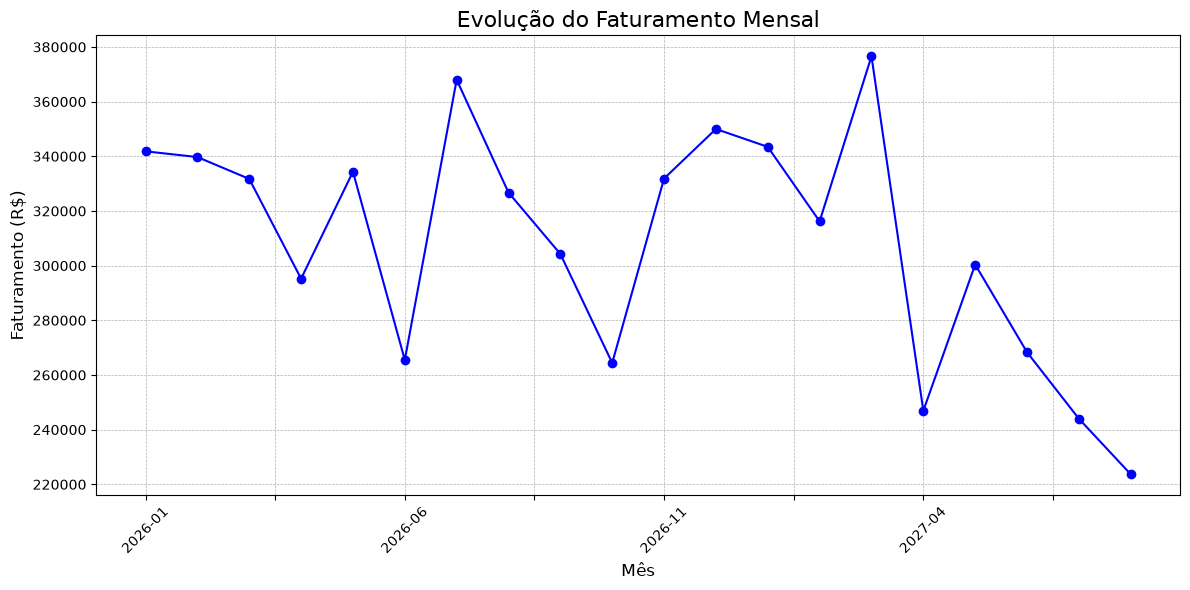

In [77]:
#Criando uma figura com tamaho 12 pro 6 pol
plt.figure(figsize = (12,6))

#Plota os dados do faturamento mensal em formato de linha
faturamento_mensal.plot(kind= 'line', marker= 'o', linestyle= '-', color= 'blue')

#Define o titulo do gráfico com fonte de tamanho 16
plt.title('Evolução do Faturamento Mensal', fontsize= 16)

#Define o rótulo do eixo x
plt.xlabel('Mês', fontsize= 12)

#define o rótulo do eixo y
plt.ylabel('Faturamento (R$)', fontsize= 12)

#Define o rótulo do eixo x em 45 graus para melhor visualização
plt.xticks(rotation= 45)

#Adiciona uma grade com estilo tracejado e linhas finas
plt.grid(True, which= 'both', linestyle= '--', linewidth= 0.5)

#Ajusta automaticamente os elementos para evitar sobreposição
plt.tight_layout()

#eXIBE O gRÁFICO
plt.show()


In [78]:
#Agrupa por estado e soma o faturamento
vendas_estado = df_vendas.groupby('Estado')['Faturamento'].sum().sort_values(ascending = False)
#Formata para duas casa decimais
vendas_estado.map('R$ {:,.2f}'.format)

Estado
AM    R$ 826,591.94
AL    R$ 819,375.66
ES    R$ 799,544.64
AC    R$ 796,346.31
CE    R$ 781,746.98
AP    R$ 737,556.23
BA    R$ 731,514.46
DF    R$ 680,645.41
Name: Faturamento, dtype: str

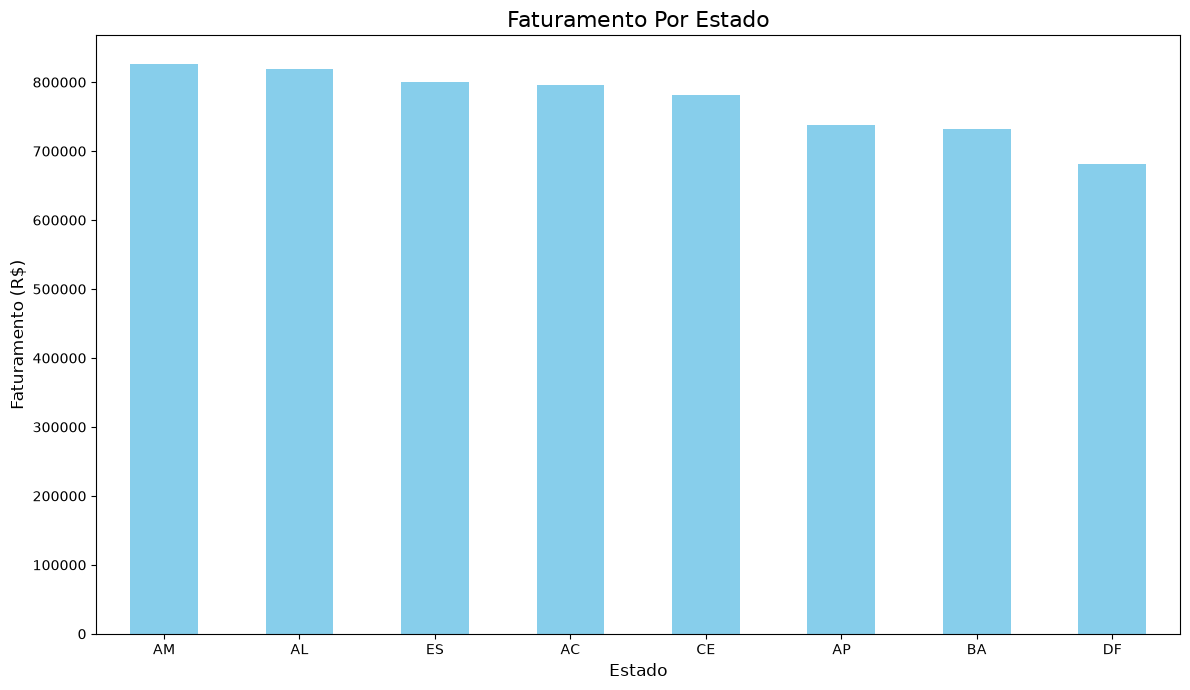

In [79]:
#Criando um figura com tamanho 12 pro 7 polegadas
plt.figure(figsize= (12, 7))

#Plota os dados de faturamento por esstado em formato de gráfico de barras
#Usando a paleta de cores "rocket" do Seaborn
vendas_estado.plot(kind= 'bar', color= 'skyblue' )

#Define o Título do gráfico com fonte de tamanho 16
plt.title('Faturamento Por Estado', fontsize= 16)

#Define o rótuo dos eixos X e Y
plt.xlabel('Estado', fontsize= 12)
plt.ylabel('Faturamento (R$)', fontsize= 12)

#Mantém os rótulos do eixo X na horizontal (sem rotação)
plt.xticks(rotation= 0)

#Ajusta automaticamento os elementos dos gráficos para evitar sobreposição
plt.tight_layout()

#Exibe o gráfico
plt.show()

In [80]:
df_vendas.head()

,ID_pedido,Data_pedido,Nome_produto,Categoria,Preco_unitario,Quantidade,Id_cliente,Cidade,Estado,Mes,Faturamento
0,1001,2026-01-01 12:00:00,Webcam Full HD,Streaming,199.9,6,3752,Ceará,CE,2026-01,1199.4
1,1002,2026-01-01 12:00:00,Gabinete com iluminação RGB,Gabinetes,399.9,7,6897,Espírito Santo,ES,2026-01,2799.3
2,1003,2026-01-01 13:00:00,Controle sem fio,Periféricos,349.9,2,6475,Distrito Federal,DF,2026-01,699.8
3,1004,2026-01-01 05:00:00,Headset gamer,Áudio,249.9,3,3626,Espírito Santo,ES,2026-01,749.7
4,1005,2026-01-01 19:00:00,Placa de vídeo,Hardware,2499.9,3,6531,Alagoas,AL,2026-01,7499.7


In [81]:
#Agrupando por categoria, soma o faturamento e formata como moeda para melhorar leitura
faturamento_categoria = df_vendas.groupby('Categoria')['Faturamento'].sum().sort_values(ascending= False)


In [82]:
#Formatando as decimais
faturamento_categoria.map('R$ {:,.2f}'.format)

Categoria
Hardware         R$ 2,218,069.20
Monitores        R$ 1,006,716.10
Móveis             R$ 748,925.10
Periféricos        R$ 672,048.63
Áudio              R$ 463,820.20
Armazenamento      R$ 388,713.60
Gabinetes          R$ 309,122.70
Streaming          R$ 157,721.10
Acessórios         R$ 112,059.00
Refrigeração        R$ 96,126.00
Name: Faturamento, dtype: str

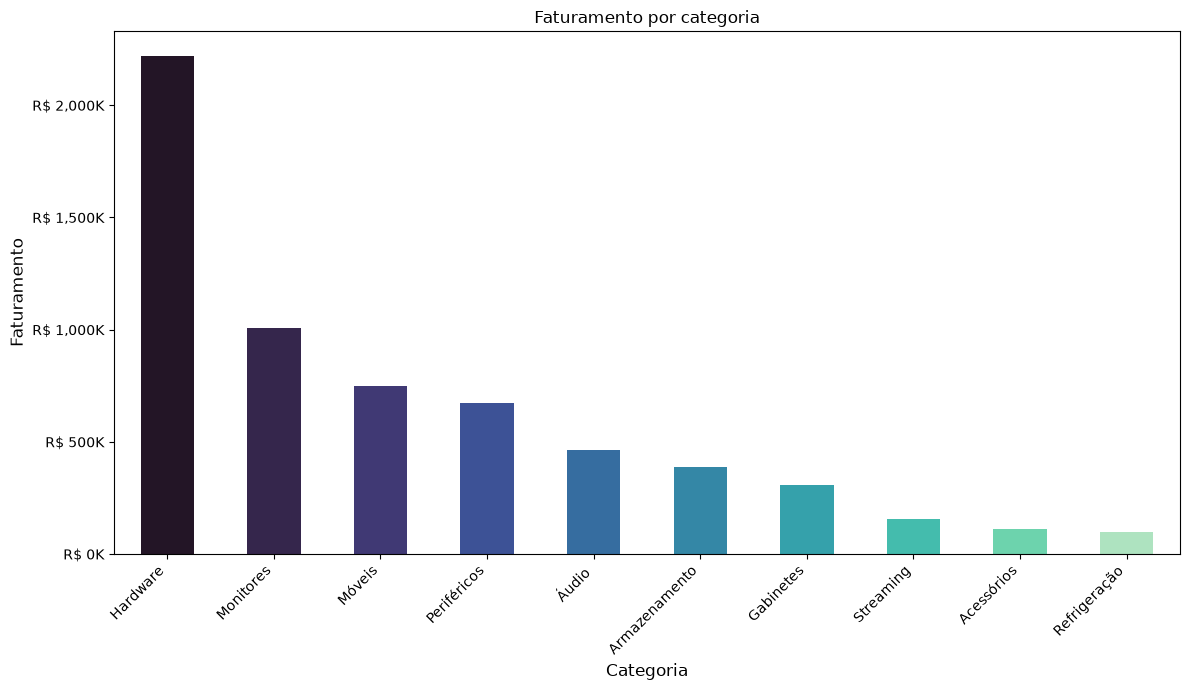

In [83]:
#Importa a função FuncFormatter para formatar os eixos
faturamento_ordenado = faturamento_categoria.sort_values(ascending= False)

#Cria a figura e os Eixos (ax) com plt.subplts()
#isso nos dá mais controle sobre os elementos gráficos
fig, ax = plt.subplots(figsize = (12, 7))

#Cria uma função para formatar os números
#Esta função recebe um valor 'y' e o transforma em uma string no formato 'R$ XXK'
def formatador_milhares(y, pos):
  """Formata o valor em milhares (k) com cifrão R$."""
  return f'R$ {y/1000:,.0f}K'

#Cria o obeto formatador
formatter = FuncFormatter(formatador_milhares)

#Aplica o formatador ao eixo Y (ax.yaxis)
ax.yaxis.set_major_formatter(formatter)

#Plota os dados usando o objeto 'ax
faturamento_ordenado.plot(kind= 'bar', ax= ax, color = sns.color_palette('mako', len(faturamento_ordenado)))

#Adiciona titulos e abels usando "ax.set_..."
ax.set_title('Faturamento por categoria', fontsize=12)
ax.set_xlabel('Categoria', fontsize=12)
ax.set_ylabel('Faturamento', fontsize=12)

#Ajudatar a rotação dos rotulos
plt.xticks(rotation= 45, ha= 'right')

#Garante que não aja sobreposição ao final
plt.tight_layout()

#Exibe o Gráfico
plt.show()